In [1]:
import pandas as pd

df = pd.read_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\cleaned_transit_data.csv")

# Determine available columns
has_trip_id = "trip_id" in df.columns

# 1. Top 10 Delayed Routes
if has_trip_id:
    top_routes = df.groupby("route_short_name").agg(
        avg_delay_min=("delay_minutes", "mean"),
        p95_delay=("delay_minutes", lambda x: x.quantile(0.95)),
        total_trips=("trip_id", "nunique")
    )
else:
    top_routes = df.groupby("route_short_name").agg(
        avg_delay_min=("delay_minutes", "mean"),
        p95_delay=("delay_minutes", lambda x: x.quantile(0.95)),
        total_observations=("delay_minutes", "count")
    )

top_routes = top_routes.sort_values(by="avg_delay_min", ascending=False)

print("--- TOP 10 DELAYED ROUTES ---")
print(top_routes.head(10))

print("\n")

# 2. Top 15 Bottleneck Stops
top_stops = df.groupby(["stop_name", "stop_lat", "stop_lon"]).agg(
    avg_delay_sec=("delay_seconds", "mean"),
    avg_delay_min=("delay_minutes", "mean"),
    observations=("delay_minutes", "count")
).sort_values(by="avg_delay_min", ascending=False)

print("--- TOP 15 BOTTLENECK STOPS ---")
print(top_stops.head(15))

--- TOP 10 DELAYED ROUTES ---
                  avg_delay_min  p95_delay  total_observations
route_short_name                                              
55                     7.896667  31.417500                  50
61                     6.062899  23.011667                1327
39                     4.718750  18.595833                  56
6                      4.625628  21.890000                 292
N68                    4.583333   5.633333                   2
37E                    4.352214  17.682500                 512
27                     4.123430  10.764167                 722
37                     3.982986  19.972500                  48
22                     3.956863   4.120000                  68
8E                     3.634055  12.540000                 277


--- TOP 15 BOTTLENECK STOPS ---
                                                    avg_delay_sec  \
stop_name                       stop_lat  stop_lon                  
Bremen Friedrich-Engels-Straße  53.050513 

In [3]:
import os
import pandas as pd

# Load the lookup metadata table
lookup_path = "./Data/bremen_lookup.csv" if os.path.exists("./Data/bremen_lookup.csv") else "bremen_lookup.csv"
df_lookup = pd.read_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\lookup_table.csv")

# Map numeric route_type to human-readable names
vehicle_map = {0: "Tram", 3: "Bus"}
df_lookup["vehicle_type"] = df_lookup["route_type"].map(vehicle_map).fillna("Bus")

# Extract unique route mappings
route_mapping = (
    df_lookup.groupby("route_short_name")
    .agg(
        vehicle_type=("vehicle_type", "first"),
        destinations=("trip_headsign", lambda x: " / ".join(sorted(x.dropna().unique()))),
        associated_route_ids=("route_id", lambda x: ", ".join(sorted(x.dropna().unique())))
    )
    .reset_index()
    .sort_values(by="route_short_name")
)

# Display mapping overview
print("=== BSAG BREMEN ROUTE MAPPING TABLE ===")
print(route_mapping.to_string(index=False))

# Export mapping table to CSV for presentation/reports
route_mapping.to_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\route_names_mapping.csv", index=False)
print("\nSaved route mapping to './Data/route_names_mapping.csv'")


=== BSAG BREMEN ROUTE MAPPING TABLE ===
route_short_name vehicle_type                                                                          destinations                        associated_route_ids
               1         Tram                                                                           Bf Mahndorf                                     35761_0
              10         Tram                                                        Bremen Sebaldsbrück (Bus+Tram)                                     35755_0
             101          Bus                                                                       Bassum, Bahnhof                                     81062_3
             102          Bus                                                    Brinkum Marktplatz / Syke, Bahnhof                            81063_3, 85834_3
             113          Bus                                                                 Bremen, Roland-Center                                     81072_3


In [1]:
import pandas as pd

# Load your cleaned transit data
file_path = r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\cleaned_transit_data.csv"
df = pd.read_csv(file_path)

# Ensure departure_timestamp is formatted as datetime
df['departure_timestamp'] = pd.to_datetime(df['departure_timestamp'])
df['Date'] = df['departure_timestamp'].dt.strftime('%Y-%m-%d')
df['Time'] = df['departure_timestamp'].dt.strftime('%H:%M:%S')

# Sort by highest delay minutes
top_10_delays = df.sort_values(by="delay_minutes", ascending=False).head(10)

# Display specific columns
columns_to_display = ['stop_name', 'route_short_name', 'delay_minutes', 'Date', 'Time']
available_cols = [col for col in columns_to_display if col in df.columns]

print("=== TOP 10 SINGLE DELAY EVENTS ===")
print(top_10_delays[available_cols].to_string(index=False))

=== TOP 10 SINGLE DELAY EVENTS ===
                            stop_name route_short_name  delay_minutes       Date     Time
                     Bremen Wasserweg               N7     119.683333 2026-08-28 07:45:00
             Bremen Grasberger Straße              N10     118.750000 2026-08-18 12:05:00
                  Bremen Campingplatz               28     118.550000 2026-08-31 19:50:00
             Bremen Grasberger Straße              N10     117.683333 2026-08-20 12:05:00
Bremen Stader Straße/Hamburger Straße                3     117.033333 2026-08-27 22:45:00
           Bremen Ricarda-Huch-Straße               27     116.816667 2026-08-31 20:50:00
                Bremen Müdener Straße               N5     114.733333 2026-08-22 22:30:00
                      Bremen Im Holze              33E     114.683333 2026-08-28 11:50:00
                  Bremen Campingplatz               28     114.083333 2026-08-29 20:00:00
                     Bremen Rosenpfad               N4     113.65

Loading data from: C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\cleaned_transit_data.csv
Successfully loaded 46,576 valid records!

--- TOP 5 BOTTLENECK STOPS ---
                  stop_name  avg_delay  total_records
Bremen Bahnhof Oslebshausen  28.445833              4
           Bremen Herdentor  25.237500              4
        Bremen Wätjenstraße  20.100000              2
             Bremen Am Wall  16.175000              2
        Bremen Herbststraße  15.341667              2


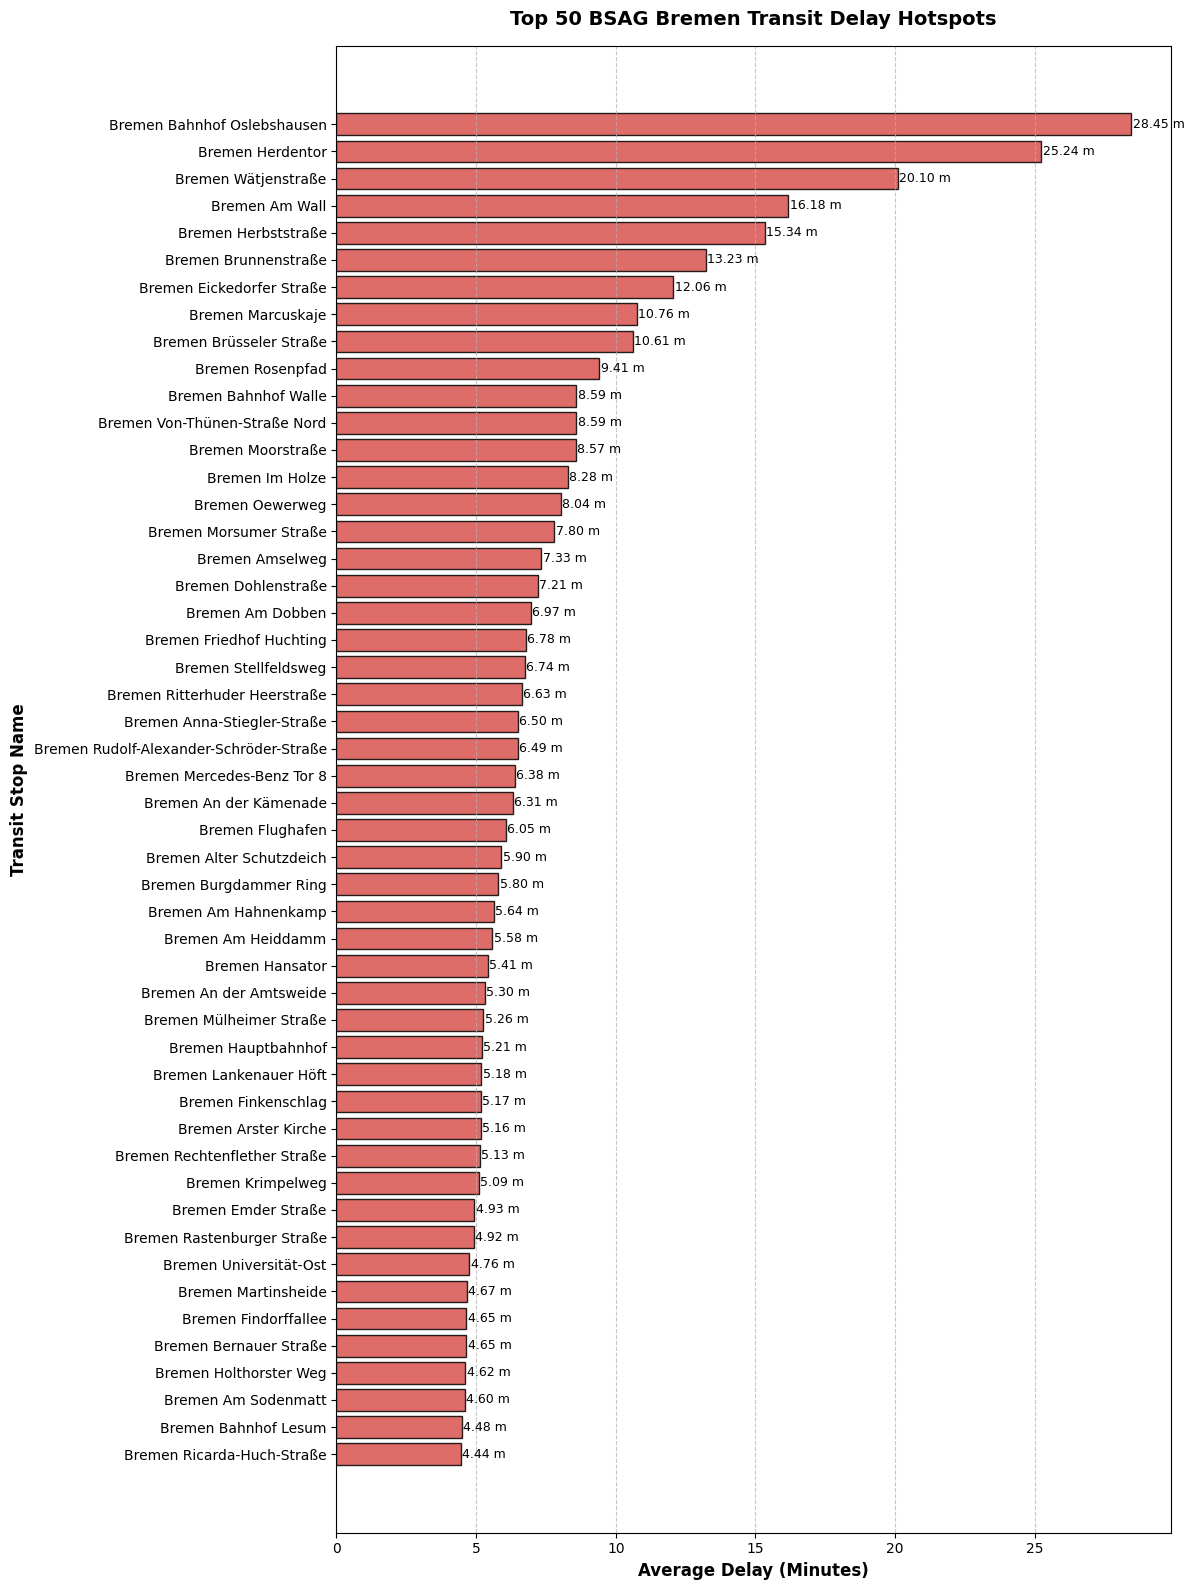


Saved visualization image as 'top50_delays_bar.png'!


In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

# Paths
PRIMARY_PATH = r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\cleaned_transit_data.csv"
FALLBACK_PATH = r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\Data\processed_transit_data.csv"

# Determine path
data_path = PRIMARY_PATH if os.path.exists(PRIMARY_PATH) else FALLBACK_PATH
print(f"Loading data from: {data_path}")

# 1. Load CSV robustly (skipping malformed/corrupt lines)
try:
    df = pd.read_csv(data_path, on_bad_lines='skip', low_memory=False)
except Exception:
    # Legacy pandas fallback (< 1.3)
    df = pd.read_csv(data_path, error_bad_lines=False, warn_bad_lines=False, low_memory=False)

print(f"Successfully loaded {len(df):,} valid records!")

# 2. Ensure delay_minutes exists and is numeric
if 'delay_minutes' not in df.columns and 'delay_seconds' in df.columns:
    df['delay_seconds'] = pd.to_numeric(df['delay_seconds'], errors='coerce')
    df['delay_minutes'] = df['delay_seconds'] / 60.0

df['delay_minutes'] = pd.to_numeric(df['delay_minutes'], errors='coerce')
df = df.dropna(subset=['delay_minutes', 'stop_name'])

# 3. Aggregate Top 50 Bottleneck Stops
top50 = (
    df.groupby("stop_name")["delay_minutes"]
    .agg(avg_delay="mean", total_records="count")
    .reset_index()
    .sort_values(by="avg_delay", ascending=False)
    .head(50)
)

print("\n--- TOP 5 BOTTLENECK STOPS ---")
print(top50.head(5).to_string(index=False))

# 4. Generate Top 50 Horizontal Bar Visualization
plt.figure(figsize=(12, 16))
# Reverse to display highest delay at the top of the chart
y_labels = top50["stop_name"][::-1]
x_values = top50["avg_delay"][::-1]

plt.barh(y_labels, x_values, color="#d9534f", edgecolor="black", alpha=0.85)

plt.xlabel("Average Delay (Minutes)", fontsize=12, fontweight="bold")
plt.ylabel("Transit Stop Name", fontsize=12, fontweight="bold")
plt.title("Top 50 BSAG Bremen Transit Delay Hotspots", fontsize=14, fontweight="bold", pad=15)
plt.grid(axis="x", linestyle="--", alpha=0.7)

# Add exact numeric labels next to bars
for index, value in enumerate(x_values):
    plt.text(value + 0.05, index, f"{value:.2f} m", va='center', fontsize=9)

plt.tight_layout()
plt.savefig("top50_delays_bar.png", dpi=300)
plt.show()

print("\nSaved visualization image as 'top50_delays_bar.png'!")

=== TOP 5 PEAK DELAY HOURS ===
 hour  avg_delay  p95_delay  trip_count
   16   3.134164  10.225833        3110
   15   3.101103  10.641667        2991
    0   2.979810   9.519167         648
   17   2.954381  10.291667        3047
    1   2.867391   9.566667         391


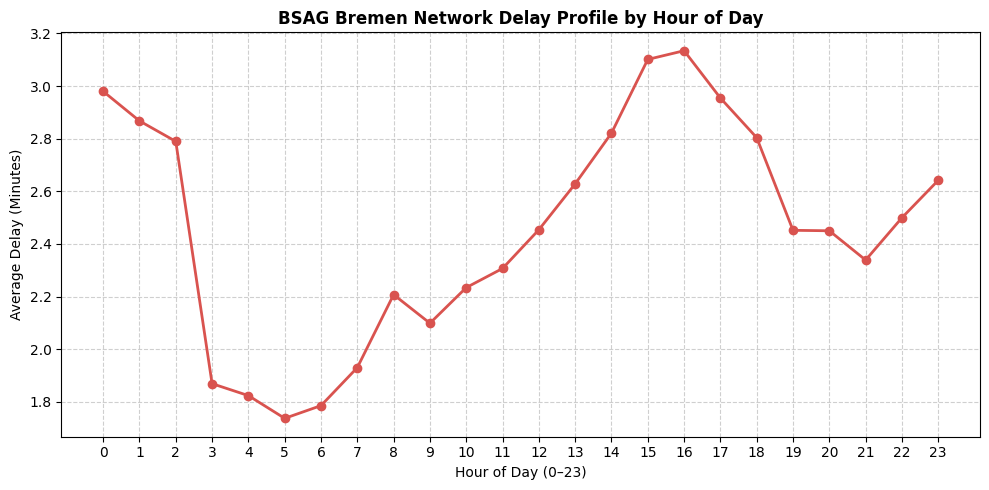

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\cleaned_transit_data.csv")

# Extract hour from timestamp
df['departure_timestamp'] = pd.to_datetime(df['departure_timestamp'])
df['hour'] = df['departure_timestamp'].dt.hour

# Calculate average delay by hour
hourly_delays = df.groupby('hour')['delay_minutes'].agg(
    avg_delay='mean',
    p95_delay=lambda x: x.quantile(0.95),
    trip_count='count'
).reset_index()

# Display top 5 peak hours
print("=== TOP 5 PEAK DELAY HOURS ===")
print(hourly_delays.sort_values(by='avg_delay', ascending=False).head(5).to_string(index=False))

# Plot hourly trend
plt.figure(figsize=(10, 5))
plt.plot(hourly_delays['hour'], hourly_delays['avg_delay'], marker='o', color='#d9534f', linewidth=2)
plt.title('BSAG Bremen Network Delay Profile by Hour of Day', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day (0–23)')
plt.ylabel('Average Delay (Minutes)')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

=== DAY-OF-WEEK DELAY PROFILE ===
 day_name  avg_delay  median_delay  p95_delay  total_trips
   Monday   2.591064      1.333333   8.000000        10931
  Tuesday   2.786155      1.341667   8.000000          762
Wednesday   2.705723      1.233333   9.920000         1293
 Thursday   2.818118      1.275000   9.910000         3032
   Friday   2.691813      1.333333   9.000000        14521
 Saturday   2.453145      1.200000   7.705000         9158
   Sunday   1.966582      1.100000   5.768333         6879


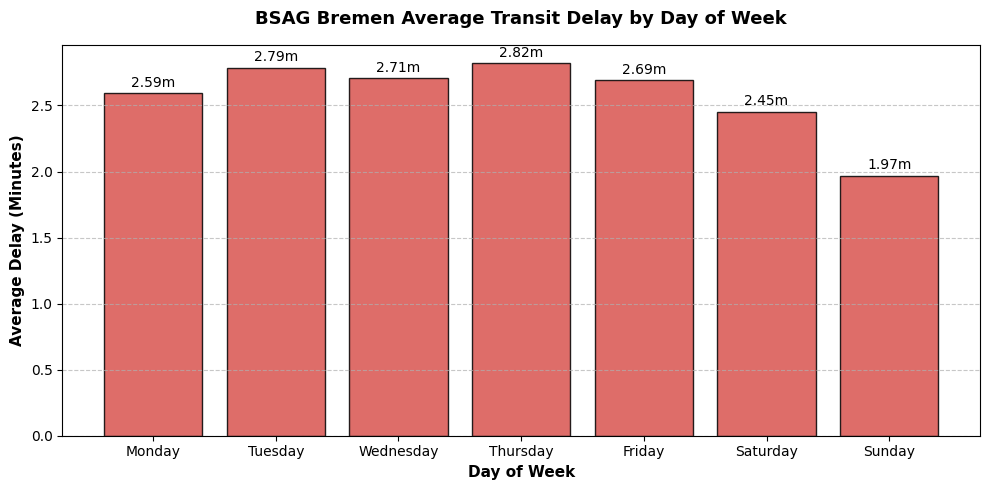

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\cleaned_transit_data.csv")

# Ensure timestamp parsing
df['departure_timestamp'] = pd.to_datetime(df['departure_timestamp'])

# Extract day of week name and order
df['day_name'] = df['departure_timestamp'].dt.day_name()
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

# Calculate delay metrics by day of week
weekly_summary = df.groupby('day_name')['delay_minutes'].agg(
    avg_delay='mean',
    median_delay='median',
    p95_delay=lambda x: x.quantile(0.95),
    total_trips='count'
).reindex(day_order).reset_index()

print("=== DAY-OF-WEEK DELAY PROFILE ===")
print(weekly_summary.to_string(index=False))

# Plot Weekly Delay Trend
plt.figure(figsize=(10, 5))
plt.bar(weekly_summary['day_name'], weekly_summary['avg_delay'], color='#d9534f', edgecolor='black', alpha=0.85)

plt.title('BSAG Bremen Average Transit Delay by Day of Week', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Day of Week', fontsize=11, fontweight='bold')
plt.ylabel('Average Delay (Minutes)', fontsize=11, fontweight='bold')
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add value labels on top of bars
for idx, row in weekly_summary.iterrows():
    if not pd.isna(row['avg_delay']):
        plt.text(idx, row['avg_delay'] + 0.05, f"{row['avg_delay']:.2f}m", ha='center', fontsize=10)

plt.tight_layout()
plt.savefig("weekly_delay_profile.png", dpi=300)
plt.show()

In [6]:
import pandas as pd

# Load dataset
df = pd.read_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\cleaned_transit_data.csv")

# Ensure numeric delays
if 'delay_minutes' not in df.columns:
    df['delay_minutes'] = df['delay_seconds'] / 60.0

# Map GTFS route_type if available (0 = Tram, 3 = Bus)
if 'route_type' in df.columns:
    df['vehicle_type'] = df['route_type'].map({0: 'Tram', 3: 'Bus'}).fillna('Bus')

# Group metrics by route
route_summary = df.groupby(['route_short_name', 'vehicle_type']).agg(
    avg_delay_min=('delay_minutes', 'mean'),
    median_delay_min=('delay_minutes', 'median'),
    p95_delay_min=('delay_minutes', lambda x: x.quantile(0.95)),
    total_observations=('delay_minutes', 'count')
).reset_index().sort_values(by='avg_delay_min', ascending=False)

print("=== TOP 10 MOST DELAYED BSAG ROUTES ===")
print(route_summary.head(10).to_string(index=False))

=== TOP 10 MOST DELAYED BSAG ROUTES ===
route_short_name vehicle_type  avg_delay_min  median_delay_min  p95_delay_min  total_observations
              1E         Tram      12.376111         13.500000      27.200000                  30
              55          Bus       7.896667          4.141667      31.417500                  50
              61          Bus       6.062899          2.700000      23.011667                1327
              39          Bus       4.718750          2.625000      18.595833                  56
               6         Tram       4.625628          2.266667      21.890000                 292
             N68          Bus       4.583333          4.583333       5.633333                   2
             37E          Bus       4.352214          2.033333      17.682500                 512
              27          Bus       4.123430          1.891667      10.764167                 722
              37          Bus       3.982986          1.266667      19.972500 

In [8]:
import pandas as pd

# Load dataset
df = pd.read_csv(r"C:\Users\yempa\OneDrive\Attachments\Documents\New folder\Digital_Transformation_project\cleaned_transit_data.csv")

# Ensure numeric delay values
if 'delay_minutes' not in df.columns:
    df['delay_minutes'] = df['delay_seconds'] / 60.0

# Map GTFS route_type (0 = Tram, 3 = Bus)
df['vehicle_type'] = df['route_type'].map({0: 'Tram', 3: 'Bus'}).fillna('Bus')

# Aggregate delay metrics by vehicle type
mode_comparison = df.groupby('vehicle_type')['delay_minutes'].agg(
    Average_Delay_Min=('mean'),
    Median_Delay_Min=('median'),
    P95_Delay_Min=lambda x: x.quantile(0.95),
    Total_Observations=('count')
).reset_index()

print("=== TRANSIT DELAY COMPARISON BY TRANSPORT MODE ===")
print(mode_comparison.to_string(index=False))

=== TRANSIT DELAY COMPARISON BY TRANSPORT MODE ===
vehicle_type  Average_Delay_Min  Median_Delay_Min  P95_Delay_Min  Total_Observations
         Bus           2.573394          1.266667       8.085000               36539
        Tram           2.345480          1.183333       7.736667               10037
